# Heart Failure

Queremos predecir la enfermedad cardiaca
Aca es más grave un FN, por lo que se debe obtener un mejor recall.

## Preparamos las librerías

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import sklearn

RANDOM_STATE = 42

ROOT = Path("..").resolve()     
DATA = ROOT / "data" / "heart.csv"
FIGURES = ROOT / "reports" / "figures"

## 01-Cargamos los datos

In [2]:
df = pd.read_csv(DATA)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [3]:
df.shape

(918, 12)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [5]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


| Variable | Tipo | Significado |
|---|---|---|
| Age | numérica | edad (años) |
| Sex | categórica (M/F) | sexo |
| ChestPainType | categórica (TA, ATA, NAP, ASY) | tipo de dolor torácico |
| RestingBP | numérica | presión arterial en reposo (mm Hg) |
| Cholesterol | numérica | colesterol sérico (mg/dl) |
| FastingBS | binaria (0/1) | glicemia en ayunas > 120 mg/dl |
| RestingECG | categórica (Normal, ST, LVH) | ECG en reposo |
| MaxHR | numérica | frecuencia cardíaca máxima alcanzada |
| ExerciseAngina | binaria (Y/N) | angina inducida por ejercicio |
| Oldpeak | numérica | depresión del segmento ST con el ejercicio |
| ST_Slope | categórica (Up, Flat, Down) | pendiente del segmento ST |
| **HeartDisease** | **objetivo (0/1)** | **enfermedad cardíaca** |

## 02-Calidad de datos

In [6]:
print("Nulos:\n")
print(df.isna().sum())
print("Duplicados:",df.duplicated().sum())

Nulos:

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Duplicados: 0


In [7]:
print(df["HeartDisease"].value_counts())
print("")
print(df["HeartDisease"].value_counts(normalize=True))

HeartDisease
1    508
0    410
Name: count, dtype: int64

HeartDisease
1    0.553377
0    0.446623
Name: proportion, dtype: float64


Vemos que hay 918 filas y 12 columnas. Donde 508 pacientes tienen enfermedad cardiáca (positivo) y 410 no tienen (negativo), su proporción es de aproximadamente del 55 % y 45 %, mostrando clases razonablemente balanceadas.

In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


Notemos que para RestingBP el mínimo es 0 y los mismo para Cholesterol, lo cual es imposible. Además Oldpeak tiene valores negativos. Las analizamos.

In [9]:
print((df["RestingBP"] == 0).value_counts())
print((df["RestingBP"] == 0).mean())
print("")
print((df["Cholesterol"] == 0).value_counts())
print((df["Cholesterol"] == 0).mean())
print("")
print((df["Oldpeak"] < 0).value_counts())

RestingBP
False    917
True       1
Name: count, dtype: int64
0.0010893246187363835

Cholesterol
False    746
True     172
Name: count, dtype: int64
0.18736383442265794

Oldpeak
False    905
True      13
Name: count, dtype: int64


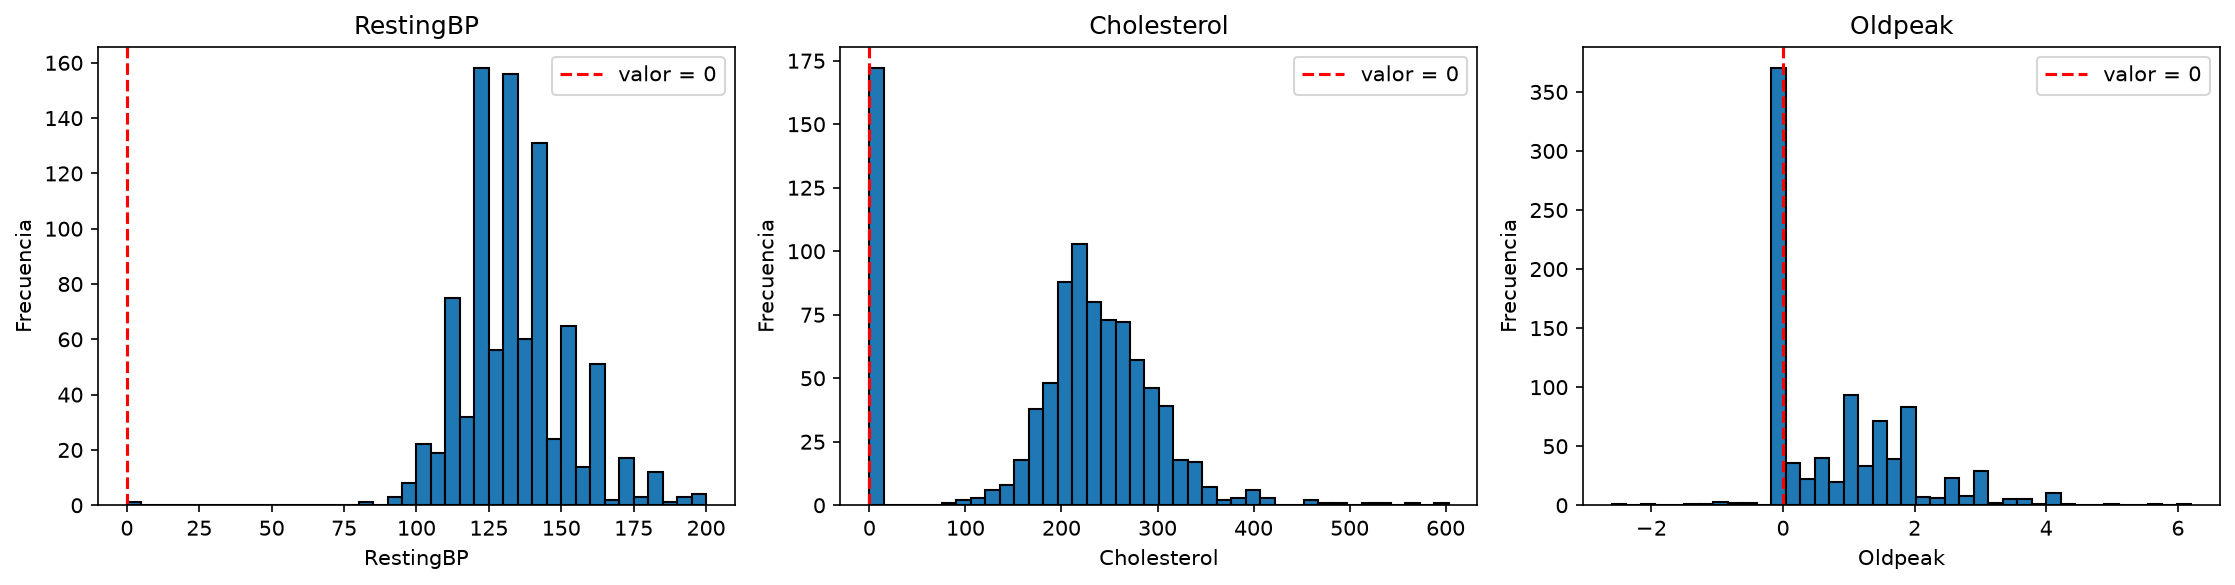

In [10]:
cols = ["RestingBP", "Cholesterol", "Oldpeak"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols):
    ax.hist(df[col], bins=40, edgecolor="black")
    ax.axvline(0, color="red", ls="--", label="valor = 0")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
    ax.legend()

plt.tight_layout()
plt.show()

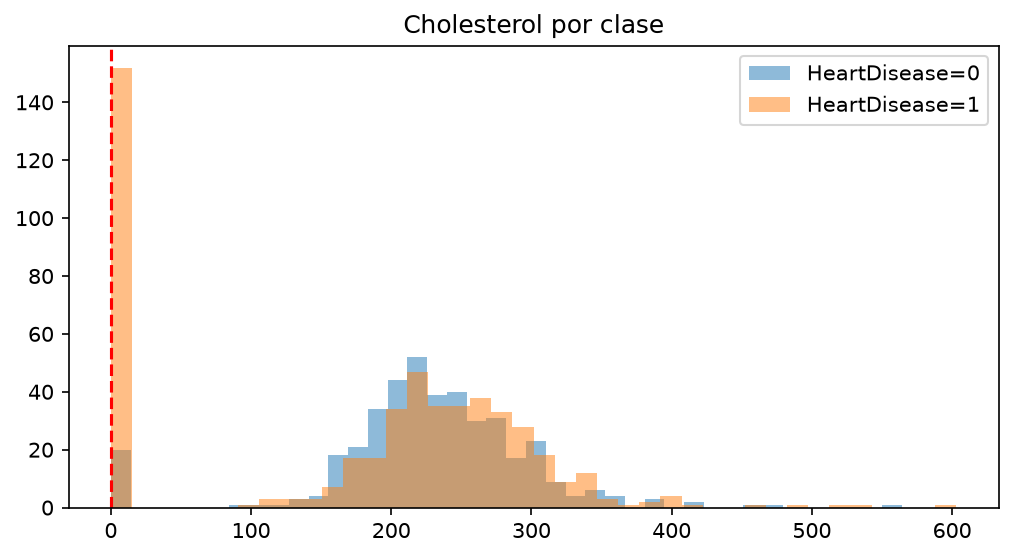

In [11]:
fig, ax = plt.subplots(figsize=(8, 4))
for clase, grupo in df.groupby("HeartDisease"):
    ax.hist(grupo["Cholesterol"], bins=40, alpha=0.5, label=f"HeartDisease={clase}")
ax.axvline(0, color="red", ls="--")
ax.set_title("Cholesterol por clase")
ax.legend()
plt.show()

In [12]:
print(df.groupby(df["Cholesterol"] == 0)["HeartDisease"].mean())

Cholesterol
False    0.477212
True     0.883721
Name: HeartDisease, dtype: float64


De acá vemos que:
- RestingBP tiene un solo valor 0, por lo que probablemente sea un error al introducir el dato. Además representa solo 1 de 918 datos (0,1 %), por lo que no hay problema en eliminarla o imputarla.

- Oldpeak es la depresión del segmento ST con el ejercicio, puede tener valores negativos como positivos.

- Cholesterol tiene 172 valores como 0, representando casi un 19% del dataset, por lo que primero, no se debe tomar tan a la ligera imputar o eliminar esas filas, y segundo, se debe investigar esos valores. Al revisar, el dataset proviene de datos de distintos hospitales, donde en uno de ellos no se midió el cholesterol y en otro parcialmente.

Otro dato importante es que aproximadamente 88% de los pacientes sin cholesterol medido, tienen la enfermedad.


**Concepto: tipos de datos faltantes.** 
- *MCAR* significa que faltan completamente al azar.
- *MAR* que faltan al azar condicionado a otras variables.
- *MNAR* que faltan por una razón relacionada con el propio valor o con el resultado. 

Aquí no es MCAR, por eso eliminar o imputar a ciegas puede sesgar el modelo.

In [13]:
print(df[df["RestingBP"] == 0].index.tolist())
# 449


[449]


In [14]:
# eliminamos la fila
df = df.drop([449])
print((df["RestingBP"] == 0).value_counts())

RestingBP
False    917
Name: count, dtype: int64


En cuanto a las 172 filas sin cholesterol, lo mejor es no eliminarlos, para evitar un sesgo, y cambiar tan drasticamente la distribución del conjunto de datos. Por lo tanto se imputan los datos. Por ahora simplemente reemplazamos los por Nan.

In [15]:
print((df["Cholesterol"] == 0).value_counts())

Cholesterol
False    746
True     171
Name: count, dtype: int64


In [16]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["Cholesterol"].isna().sum()

np.int64(171)

## 03-EDA

Primero separamos los datos numéricos y categóricos.

In [17]:
# Escribimos una lista con las columnas numéricas
num_cols = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]

# Escribimos una lista con las columnas categóricas
cat_cols = ["Sex", "ChestPainType", "FastingBS", "RestingECG", "ExerciseAngina", "ST_Slope"]

# definimos el target
target = "HeartDisease"

# Aca verificamos que ninguna columna quedó fuera
assert set(num_cols + cat_cols + [target]) == set(df.columns)

Realizamos los gráficos univariados para ver las distribuciones

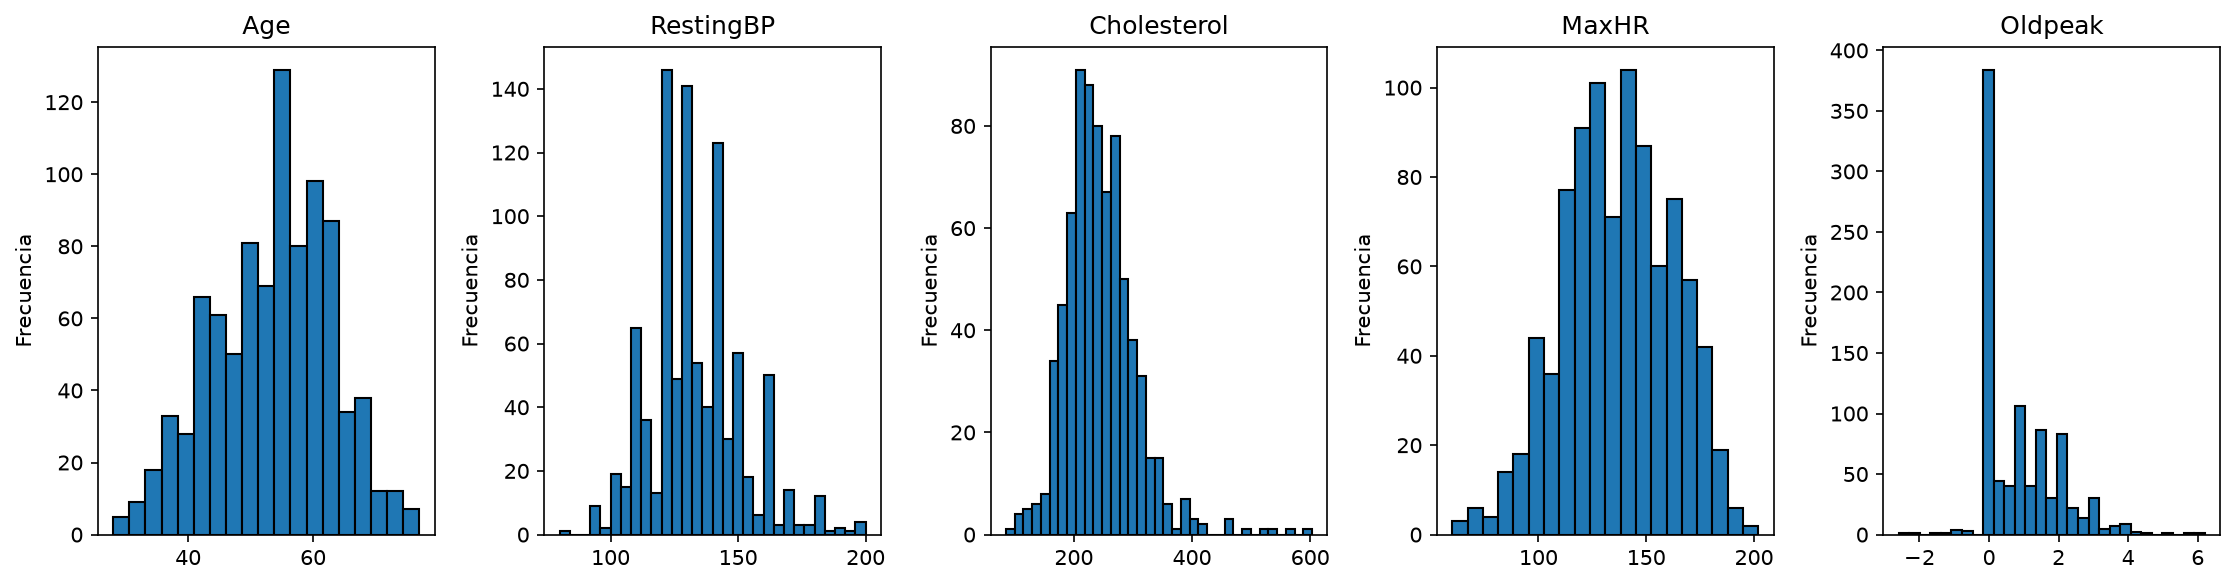

In [18]:
# Para columnas numéricas es mejor usar histogramas

# n° filas, n° columnas, tamaño
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
# Necesitas recorrer dos listas a la vez y en pareja: el primer eje con la primera columna,
# el segundo con la segunda, y así. zip las une elemento por elemento.
for ax, col in zip(axes.flat, num_cols):
    ax.hist(df[col], bins="auto", edgecolor="black")
    ax.set_title(col)
    ax.set_ylabel("Frecuencia")

# plt.tight_layout() ajusta automáticamente los espacios entre los subgráficos y los bordes de la figura para que los elementos no se encimen ni queden cortados.
plt.tight_layout()
plt.savefig(FIGURES / "num_cols-hist.png", dpi=300, bbox_inches="tight")
plt.show()




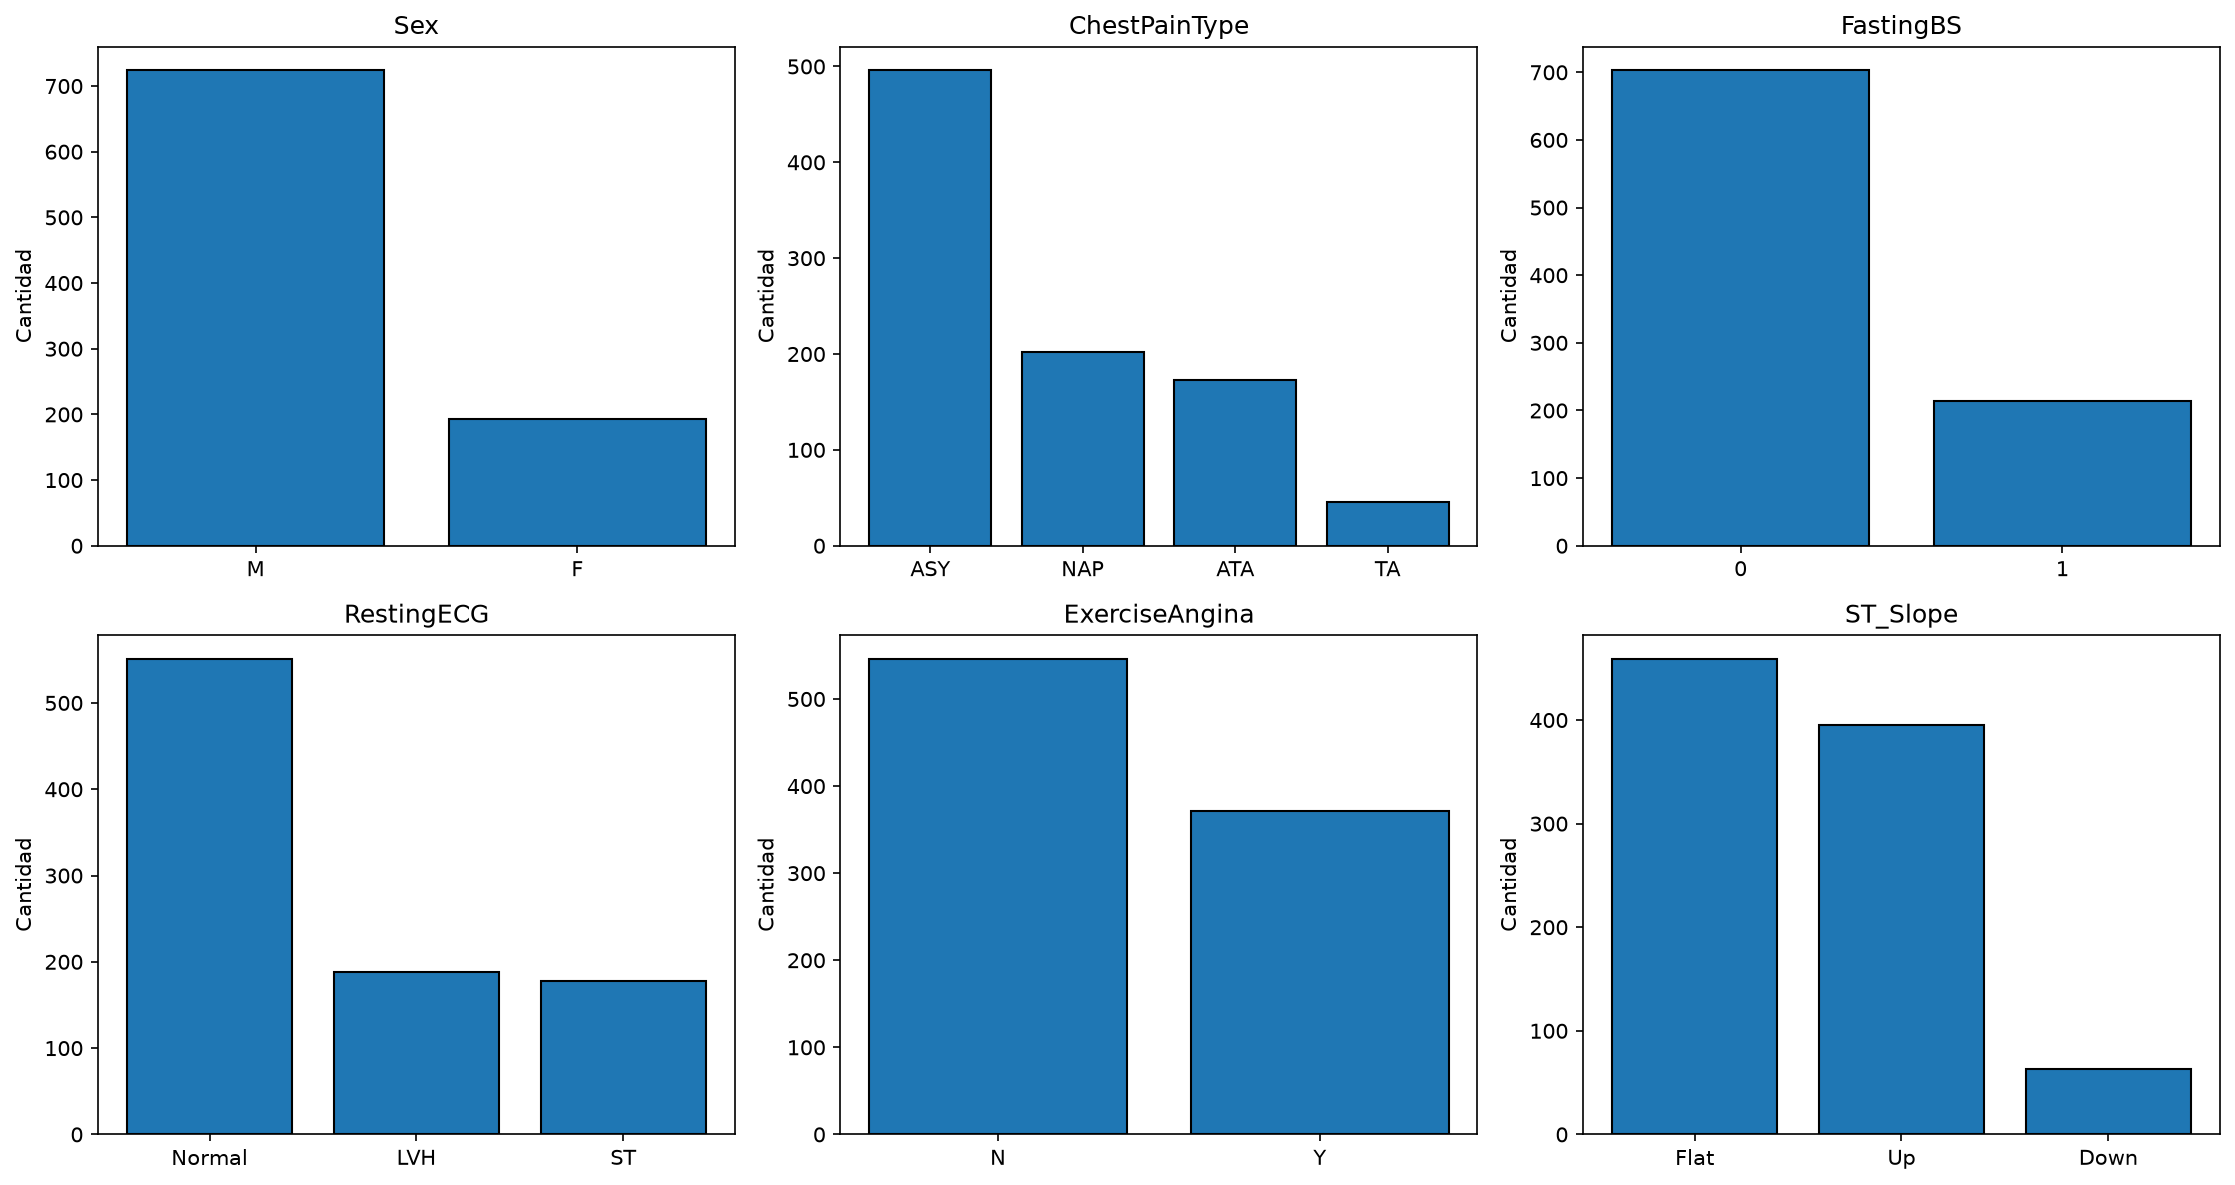

In [19]:
# n° filas, n° columnas, tamaño

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, cat_cols):
    # Necesitamos la altura de cada barra
    conteo = df[col].value_counts() # Serie: índice = categorías, valores = cantidades
    ax.bar(conteo.index.astype(str), conteo.values,  edgecolor="black")
    ax.set_title(col)
    ax.set_ylabel("Cantidad")
    

plt.tight_layout()
plt.savefig(FIGURES / "cat_cols-bar.png", dpi=300, bbox_inches="tight")
plt.show()

Ahora realizamos los gráficos bivariados con la variable objetivo

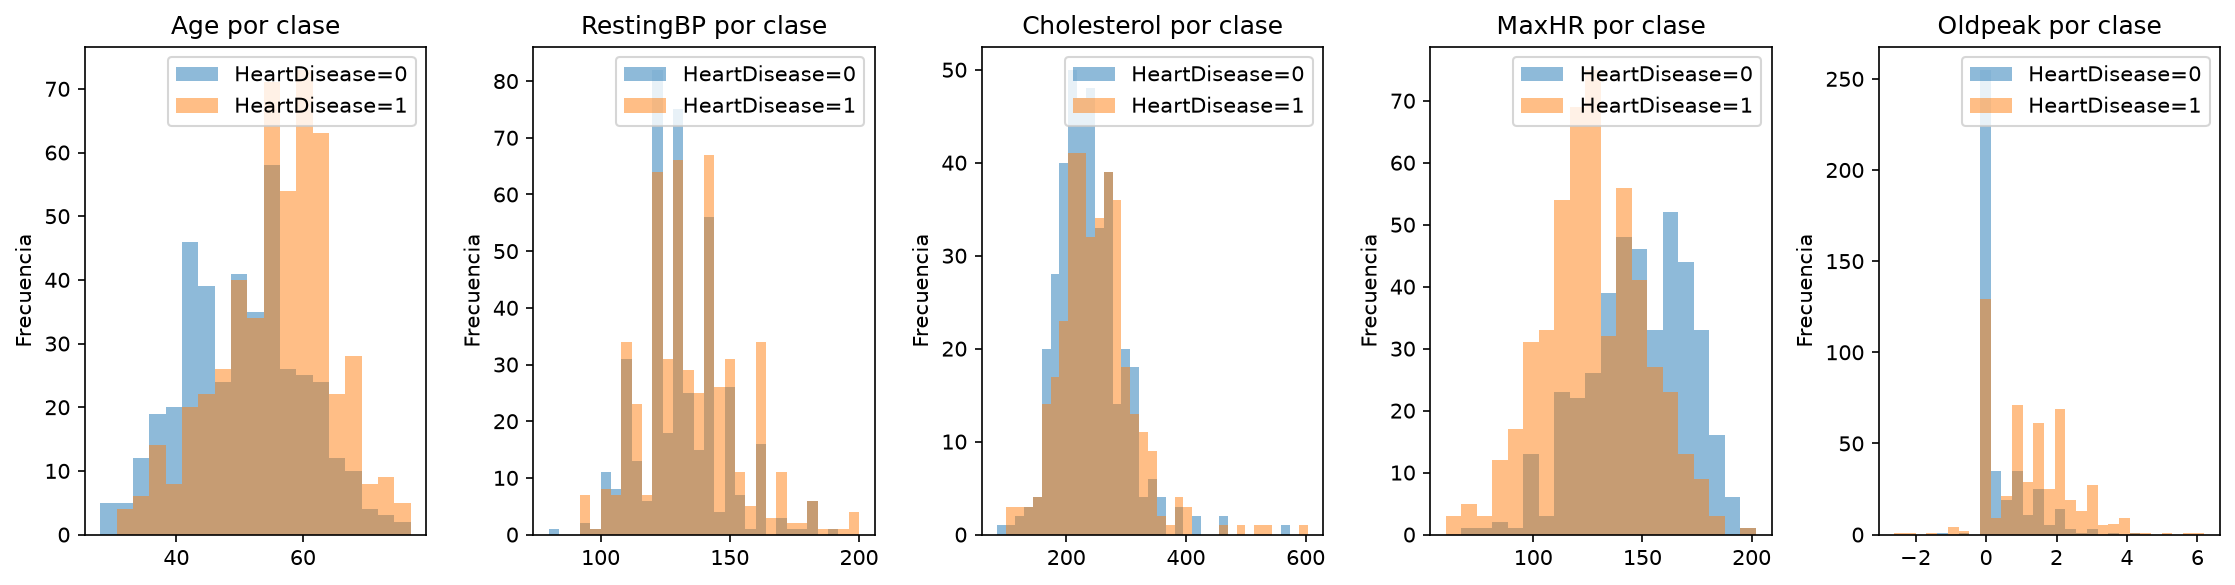

In [20]:

fig, axes = plt.subplots(1, 5, figsize=(15, 4))

for ax, col in zip(axes.flat, num_cols):
    bordes = np.histogram_bin_edges(df[col].dropna(), bins="auto")
    for clase, grupo in df.groupby("HeartDisease"):
        ax.hist(grupo[col], bins=bordes, alpha=0.5, label=f"HeartDisease={clase}")
    
    ax.set_title(f"{col} por clase")
    ax.set_ylabel("Frecuencia")
    ax.legend()
   
plt.tight_layout()
plt.show()


In [21]:
def boxplot_vs_target(data, col, target="HeartDisease", nombre_archivo=None):
    """Dibuja un boxplot por variable numérica, separando por la clase del objetivo."""
    fig, ax = plt.subplots(figsize=(8, 4))

    sin_enf = data.loc[data[target] == 0, col].dropna()
    con_enf = data.loc[data[target] == 1, col].dropna()
    ax.boxplot([sin_enf, con_enf], tick_labels=["Sin enfermedad (0)", "Con enfermedad (1)"])
    ax.set_title(f"{col} según {target}")
    ax.set_ylabel(col)
    
    plt.tight_layout()
    if nombre_archivo:
        fig.savefig(FIGURES / nombre_archivo, dpi=300, bbox_inches="tight")
    plt.show()

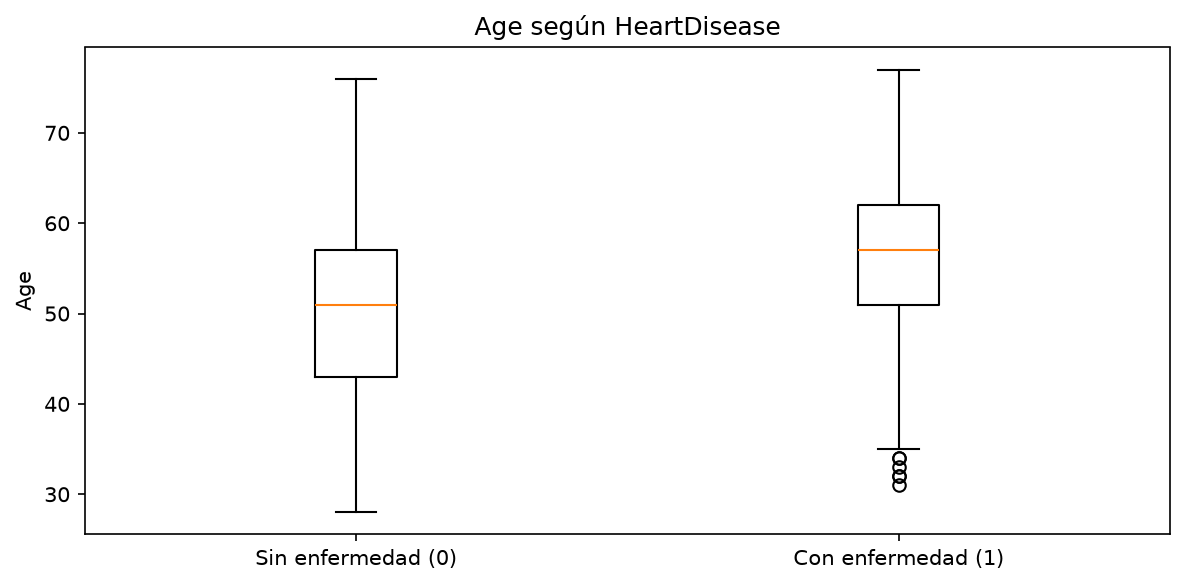

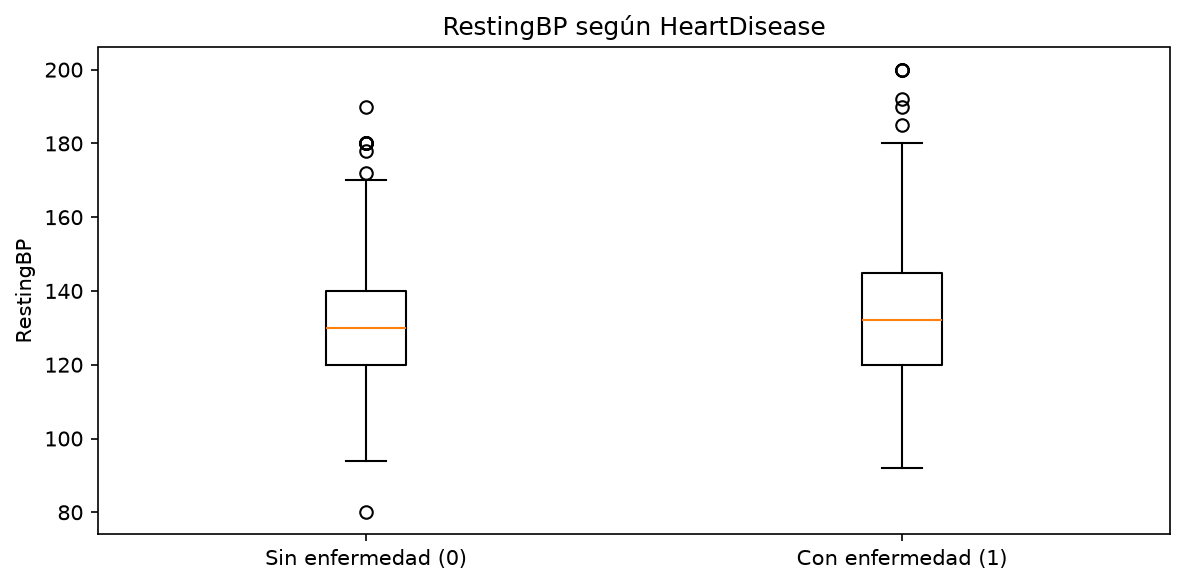

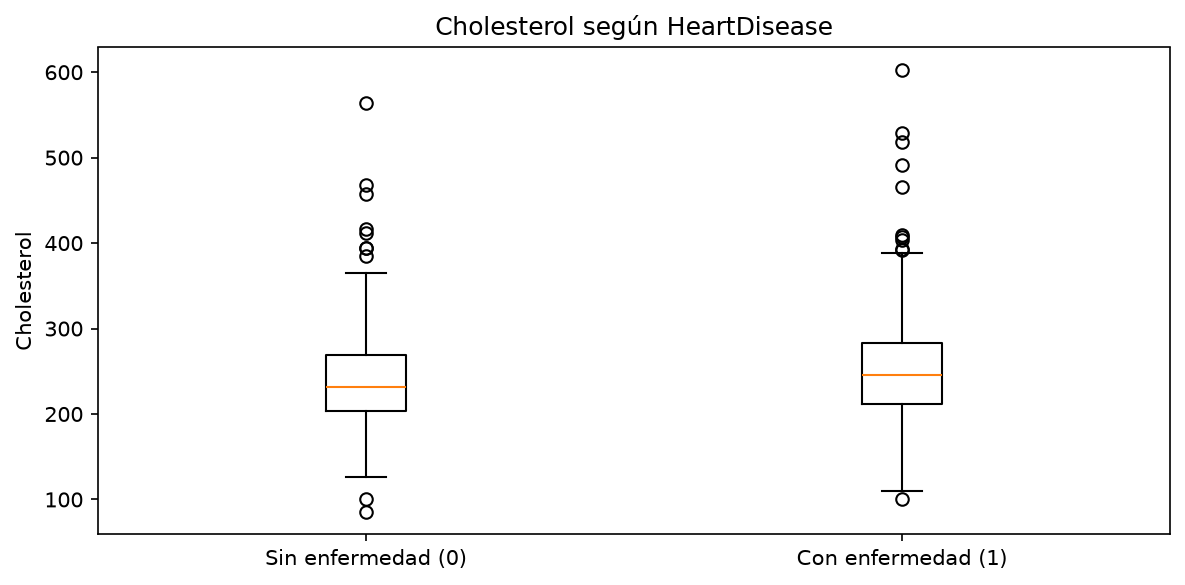

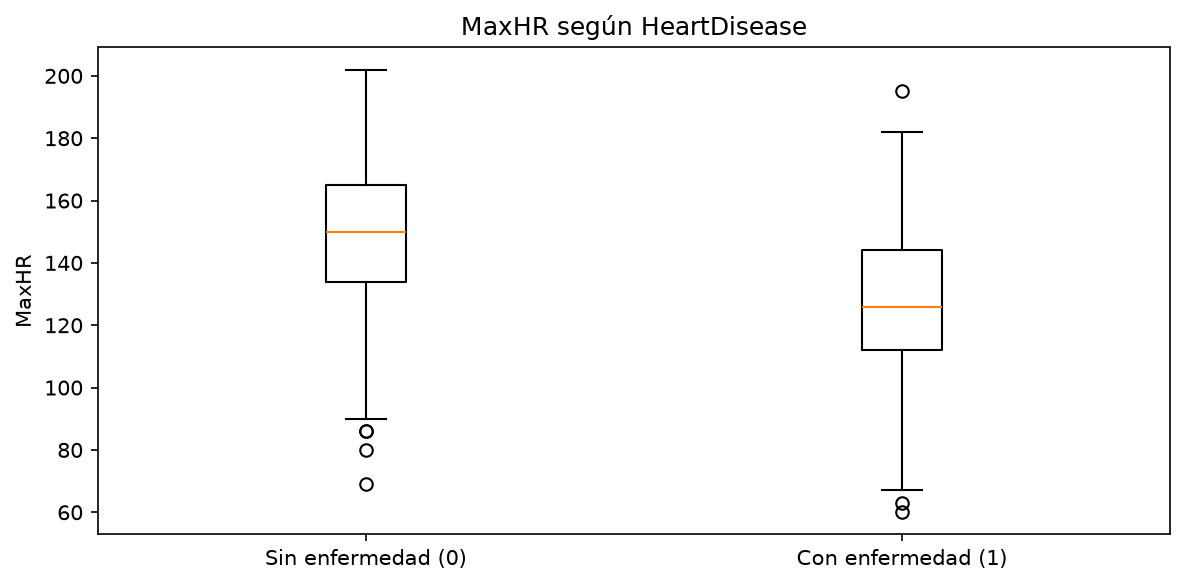

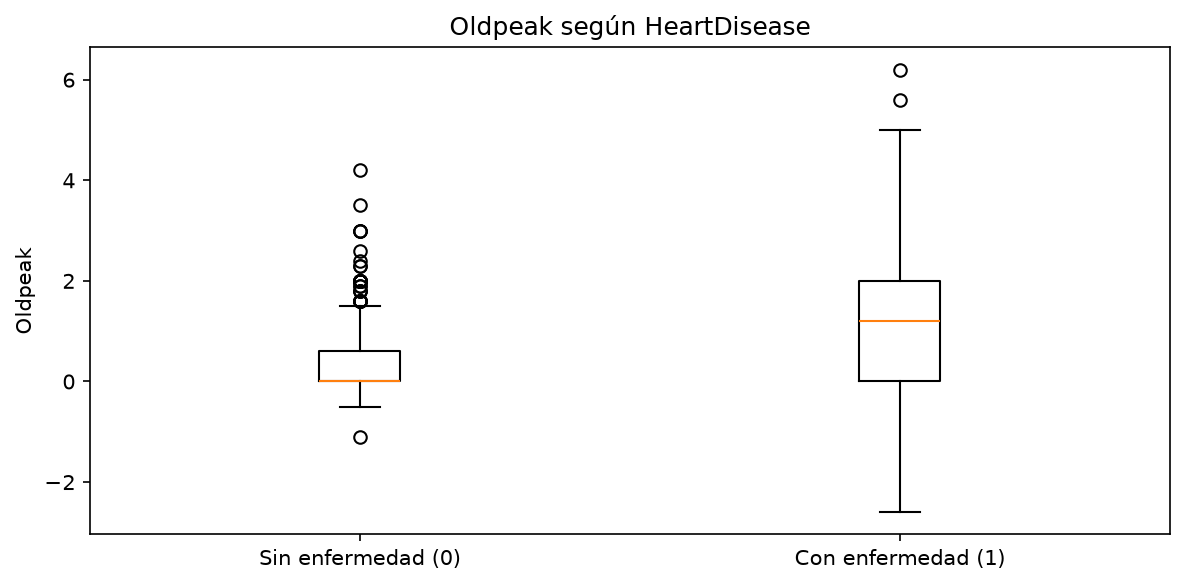

In [22]:
for col in num_cols:
    boxplot_vs_target(df, col, nombre_archivo=f"boxplot-{col}.png")

Vemos que:
- Para Age las personas con enfermedad se concentran en personas de mayor edad, aproximadamente entre los 50 y 65 años, con una mediana cerca de los 60 años.
- En RestingBP, la distribución entre las personas con y sin la enfermedad es leve.
- En Cholesterol no hay mucha diferencia entre la distribución entre personas con enfermedad y sin la enfermedad.
- En MaxHR las personas con la enfermadad se concentran entre los 100 y 150 latidos, con una concentración mayor entre los 115 y 130 latidos. Y junto al boxplot se puede ver que los pacientes enfermos alcanzan un frecuencia máxima más baja, con una mediana de 150 de los no enfermos y 126 de los enfermos.
- Se observa que en Oldpeak, gran parte de las personas con la enfermedad están distribuidos entre los valores 1 y 2, siendo más frecuente en ese rango que las personas sin la enfermedad.

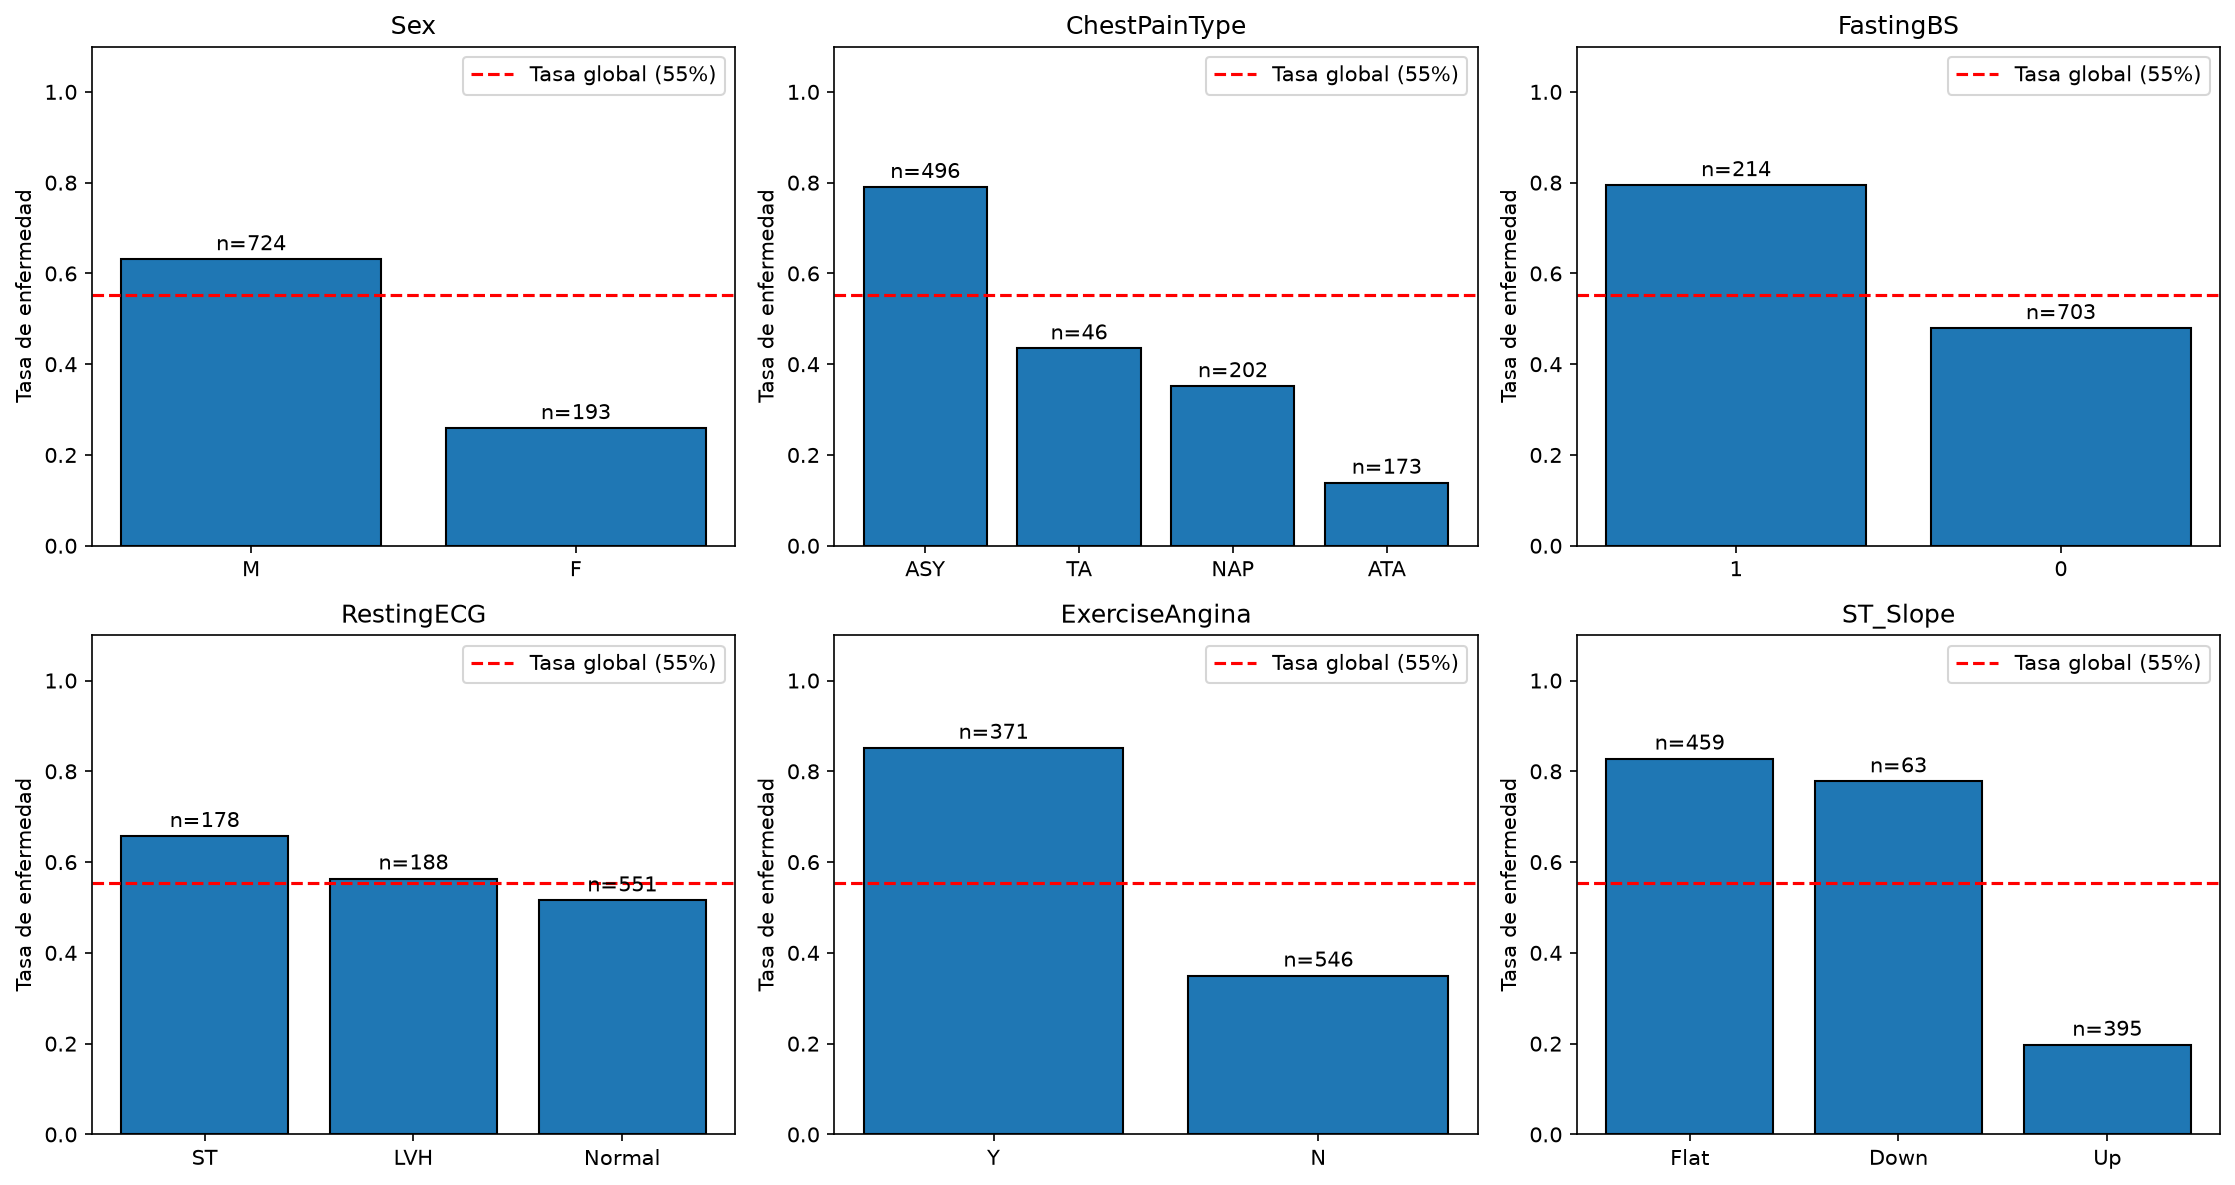

In [23]:
tasa_global = df[target].mean()

fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, cat_cols):
    # proporción de enfermos por categoría, ordenada de mayor a menor
    tasa = df.groupby(col)[target].mean().sort_values(ascending=False)
    # Necesitamos la altura de cada barra (cantidad de pacientes)
    conteo = df[col].value_counts() # Serie: índice = categorías, valores = cantidades
    ax.bar(tasa.index.astype(str), tasa.values, edgecolor="black")
    ax.axhline(tasa_global, color="red", ls="--", label=f"Tasa global ({tasa_global:.0%})")
    
    for i, cat in enumerate(tasa.index):
        ax.text(i, tasa[cat] + 0.02, f"n={conteo[cat]}", ha="center")

    ax.set_ylim(0, 1.1)
    ax.set_title(col)
    ax.set_ylabel("Tasa de enfermedad")
    ax.legend(loc="upper right")
    

plt.tight_layout()
plt.savefig(FIGURES / "cat_cols-tasa.png", dpi=300, bbox_inches="tight")
plt.show()

Vemos que:
- Los hombres tienen una mayor tasa de enfermedad, superando el 60% de la tasa, con 724 pacientes.
- En ChestPainType, ASY; los asintomáticos, tienen una mayor tasa de la enfermedad, casi el 80%.
- En FastingBS, los pacientes con >120 mg/dl tienen mayor tasa de enfermedad, llegando casi al 80%, y siendo de menor cantidad con los que tienen <=120 mg/dl.
- En RestingECG, los pacientes que presentan la anomalía de la onda ST-T tienen una mayor tasa de enfermedad. Sin embargo no hay mucha diferencia con las otras características.
- En los pacientes que tuvieron Angina después del ejercicio, tienen una mayor tasa de enfermedad, superando el 80%, y siendo solamente 371 pacientes.
- Para ST_Slope vemos que Flat  y Down se asocian a una mayor tasa de enfermedad, superando el 80%.

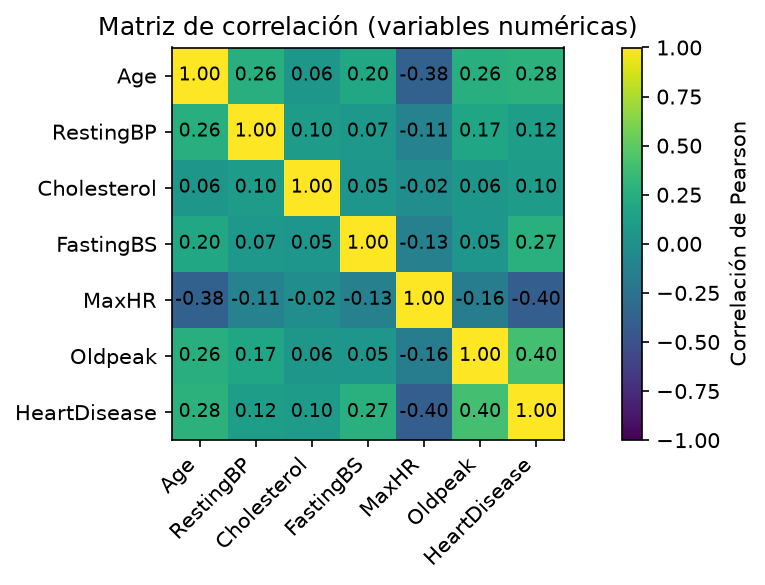

In [24]:
# obtenemos la matriz de correlación

corr = df.select_dtypes(include="number").corr()

# la graficamos

fig, ax = plt.subplots(figsize=(8, 4))
im = ax.imshow(corr, vmin=-1, vmax=1)

# Nombres de las variables en los ejes
ax.set_xticks(range(len(corr.columns)), labels=corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), labels=corr.index)

# Escribir el valor en cada celda
for i in range(len(corr.index)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)

fig.colorbar(im, ax=ax, label="Correlación de Pearson")
ax.set_title("Matriz de correlación (variables numéricas)")

plt.tight_layout()
plt.show()

Notemos que Oldpeak con 0.40, MaxHR con -0.40, Age con 0.28 y FastingBS son las características numéricas con mayor correlación. RestingBp y Cholesterol apenas se correlacionan.

## 04-Separación train y test

In [25]:
from sklearn.model_selection import train_test_split
X = df.drop(target, axis=1)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y,random_state=RANDOM_STATE)

In [26]:
# verificamos el stratify
print(y_train.value_counts(normalize=True).round(3))
print(y_test.value_counts(normalize=True).round(3))

HeartDisease
1    0.553
0    0.447
Name: proportion, dtype: float64
HeartDisease
1    0.554
0    0.446
Name: proportion, dtype: float64


## 05-Preprocesamiento; imputamos y realizamos el pipeline

In [27]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder


# usamos mediana en este caso porque es más robusta a outliers
# escalamos porque modelos como regresión logística o KNN son sensibles a la escala
steps_num = [("imputation", SimpleImputer(strategy="median", add_indicator=True)),
                ("scaler", StandardScaler())]

num_pipe = Pipeline(steps_num)

# aca usamos onehotencoder para convertir las categóricas
# usamos drop="if_binary" para dropear una columnas en características de dos categorías; como "Sex"
steps_cat = [("onehot", OneHotEncoder(handle_unknown="ignore", drop="if_binary"))]

cat_pipe = Pipeline(steps_cat)

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

In [28]:
X_train_prep = preprocessor.fit_transform(X_train)
print(X_train_prep.shape)             
print(preprocessor.get_feature_names_out())

(733, 19)
['num__Age' 'num__RestingBP' 'num__Cholesterol' 'num__MaxHR' 'num__Oldpeak'
 'num__missingindicator_Cholesterol' 'cat__Sex_M' 'cat__ChestPainType_ASY'
 'cat__ChestPainType_ATA' 'cat__ChestPainType_NAP' 'cat__ChestPainType_TA'
 'cat__FastingBS_1' 'cat__RestingECG_LVH' 'cat__RestingECG_Normal'
 'cat__RestingECG_ST' 'cat__ExerciseAngina_Y' 'cat__ST_Slope_Down'
 'cat__ST_Slope_Flat' 'cat__ST_Slope_Up']


## 06-Modelo base (baseline)

In [29]:
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

baseline = DummyClassifier(strategy="most_frequent")

kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = ["accuracy", "recall", "precision", "f1", "roc_auc"]

pipe_baseline = Pipeline([("pre", preprocessor), ("model", baseline)])

res = cross_validate(pipe_baseline, X_train, y_train, cv=kf, scoring=scoring)

pd.DataFrame(res).filter(like="test_").agg(["mean", "std"]).round(3)



,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
mean,0.553,1.0,0.553,0.712,0.5
std,0.002,0.0,0.002,0.002,0.0


Notemos que el modelo dummy tiene un recall de 1, ya que predice a la clase mayoritaria, que es la clase 1 (pacientes con enfermedad), pero al ver la precision; que es 0.553, es decir la proporción de pacientes enfermos, y el roc-auc de 0.5, vemos que el modelo no se desempeña tan bien y no diferencia entre clases. Por lo que no es bueno prediciendo.

In [30]:
# ahora aplicamos la regresión logística

from sklearn.linear_model import LogisticRegression

logreg = LogisticRegression()

pipe_logreg = Pipeline([("pre", preprocessor), ("model", logreg)])

res_logreg = cross_validate(pipe_logreg, X_train, y_train, cv=kf, scoring=scoring)

pd.DataFrame(res_logreg).filter(like="test_").agg(["mean", "std"]).round(3)


,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
mean,0.862,0.896,0.864,0.879,0.924
std,0.031,0.021,0.056,0.022,0.025


Ahora notamos que el recall baja a 0.90, el cual sigue siendo alto, pero también el accuracy es del 0.86 y el f1 es de 0.88, por lo que hay una mejor relación entre recall y precision, y viendo el roc-auc, este llega al 0.92. Por lo que se obtiene un modelo mucho mejor que el baseline anterior, el cual si logra diferenciar entre las clases.

## 07-Comparamos modelos

In [31]:
# definimos una función utilizando lo anterior

resultados, desviaciones = {}, {}
def evaluar(nombre, modelo):
    pipe = Pipeline([("pre", preprocessor), ("model", modelo)])
    res = cross_validate(pipe, X_train, y_train, cv=kf, scoring=scoring)
    metricas = pd.DataFrame(res).filter(like="test_")
    resultados[nombre] = metricas.mean()
    desviaciones[nombre] = metricas.std()

    return pd.DataFrame(resultados).T.round(3)




In [32]:
evaluar("Dummy", DummyClassifier(strategy="most_frequent"))


,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.553,1.0,0.553,0.712,0.5


In [33]:
evaluar("Logistic Regression", LogisticRegression())

,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.553,1.000,0.553,0.712,0.500
Logistic Regression,0.862,0.896,0.864,0.879,0.924


In [34]:
from sklearn.neighbors import KNeighborsClassifier
evaluar("KNN", KNeighborsClassifier())

,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.553,1.000,0.553,0.712,0.500
Logistic Regression,0.862,0.896,0.864,0.879,0.924
KNN,0.849,0.874,0.859,0.864,0.896


In [35]:
from sklearn.tree import DecisionTreeClassifier
evaluar("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE))

,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.553,1.000,0.553,0.712,0.500
Logistic Regression,0.862,0.896,0.864,0.879,0.924
KNN,0.849,0.874,0.859,0.864,0.896
Decision Tree,0.806,0.832,0.823,0.826,0.803


In [36]:
from sklearn.ensemble import RandomForestClassifier
evaluar("Random Forest", RandomForestClassifier(random_state=RANDOM_STATE))

,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.553,1.000,0.553,0.712,0.500
Logistic Regression,0.862,0.896,0.864,0.879,0.924
KNN,0.849,0.874,0.859,0.864,0.896
Decision Tree,0.806,0.832,0.823,0.826,0.803
Random Forest,0.855,0.901,0.850,0.874,0.932


In [37]:
from sklearn.ensemble import HistGradientBoostingClassifier
evaluar("Gradient Boosting", HistGradientBoostingClassifier(random_state=RANDOM_STATE))

,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.553,1.000,0.553,0.712,0.500
Logistic Regression,0.862,0.896,0.864,0.879,0.924
KNN,0.849,0.874,0.859,0.864,0.896
Decision Tree,0.806,0.832,0.823,0.826,0.803
Random Forest,0.855,0.901,0.850,0.874,0.932
Gradient Boosting,0.854,0.874,0.866,0.869,0.926


In [38]:
#vemos las desviaciones
pd.DataFrame(desviaciones).T.round(3)

,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.002,0.000,0.002,0.002,0.000
Logistic Regression,0.031,0.021,0.056,0.022,0.025
KNN,0.028,0.058,0.047,0.024,0.020
Decision Tree,0.028,0.047,0.047,0.023,0.031
Random Forest,0.032,0.029,0.050,0.023,0.019
Gradient Boosting,0.020,0.035,0.041,0.016,0.015


Como es un problema clínico y nos importa evitar los falsos negativos, priorizamos el recall como también el roc-auc.

Vemos que tanto los modelos de Logistic Regression, Random Forest y Gradient Boosting, están empatados, los dos primeros tienen un recall de 0.90 y el tercero de 0.87, y su roc-auc es de 0.92, 0.93 y 0.93, respectivamente. Y tanto en el recall como en roc-auc las diferencias son menores que sus desviaciones estándar en sus folds, quedando empatados.

Sin embargo, los modelos como Random Forest y Gradient Boosting son modelos más complejos que una Logistic Regression, y además este último es más interpretable, lo cual es aún más valioso en un contexto clínico.

In [39]:
from sklearn.model_selection import GridSearchCV

pipe_rf = Pipeline([("pre", preprocessor), ("model", RandomForestClassifier(random_state=RANDOM_STATE))])
param_grid = {
    "model__max_depth": [3, 5, 8, None],
    "model__min_samples_leaf": [1, 5, 10],
}

# de momento usamos el roc-auc para indicar el ganador, ya que indica la capacidad de separación de las clases
grid_rf = GridSearchCV(pipe_rf, param_grid, cv=kf, scoring="roc_auc")
grid_rf.fit(X_train, y_train)

print(grid_rf.best_params_, round(grid_rf.best_score_, 3))

{'model__max_depth': 5, 'model__min_samples_leaf': 1} 0.934


In [40]:
# probamos con el modelo de regresión logística

# un C más bajo -> modelo más simple
param_grid = {
    "model__C": [0.01, 0.1, 1, 10]
}

grid_logreg = GridSearchCV(pipe_logreg, param_grid, cv=kf, scoring="roc_auc")
grid_logreg.fit(X_train, y_train)

print(grid_logreg.best_params_, round(grid_logreg.best_score_, 3))

{'model__C': 0.1} 0.925


Vemos que para ambos modelos, el GridSearch apenas mejoró el roc-auc; RF pasó de 0.932 a 0.934 y Logistic Regression pasó de 0.924 a 0.925, sin embargo siguen siendo una mejora, ya que en RF el mejor max_depth fue 5, por lo que los árboles no crecen hasta memorizar cada paciente, disminuyendo el overfitting con el mismo rendimiento, y en Logistic Regression con un C=0.1, hay más regularización, así los coeficientes son más pequeños y estables.

Por lo tanto elegimos como modelo final Logistic Regression con un C=0.1, principalmente a que es un modelo más simple y más interpretable.



In [41]:
evaluar("LogReg C=0.1", LogisticRegression(C=0.1))


,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.553,1.000,0.553,0.712,0.500
Logistic Regression,0.862,0.896,0.864,0.879,0.924
KNN,0.849,0.874,0.859,0.864,0.896
Decision Tree,0.806,0.832,0.823,0.826,0.803
Random Forest,0.855,0.901,0.850,0.874,0.932
Gradient Boosting,0.854,0.874,0.866,0.869,0.926
LogReg C=0.1,0.862,0.901,0.860,0.879,0.925


In [42]:
pd.DataFrame(desviaciones).T.round(3)

,test_accuracy,test_recall,test_precision,test_f1,test_roc_auc
Dummy,0.002,0.000,0.002,0.002,0.000
Logistic Regression,0.031,0.021,0.056,0.022,0.025
KNN,0.028,0.058,0.047,0.024,0.020
Decision Tree,0.028,0.047,0.047,0.023,0.031
Random Forest,0.032,0.029,0.050,0.023,0.019
Gradient Boosting,0.020,0.035,0.041,0.016,0.015
LogReg C=0.1,0.019,0.037,0.047,0.012,0.020


## 08-Evaluación final

              precision    recall  f1-score   support

        Sano       0.88      0.87      0.87        82
     Enfermo       0.89      0.90      0.90       102

    accuracy                           0.89       184
   macro avg       0.88      0.88      0.88       184
weighted avg       0.89      0.89      0.89       184



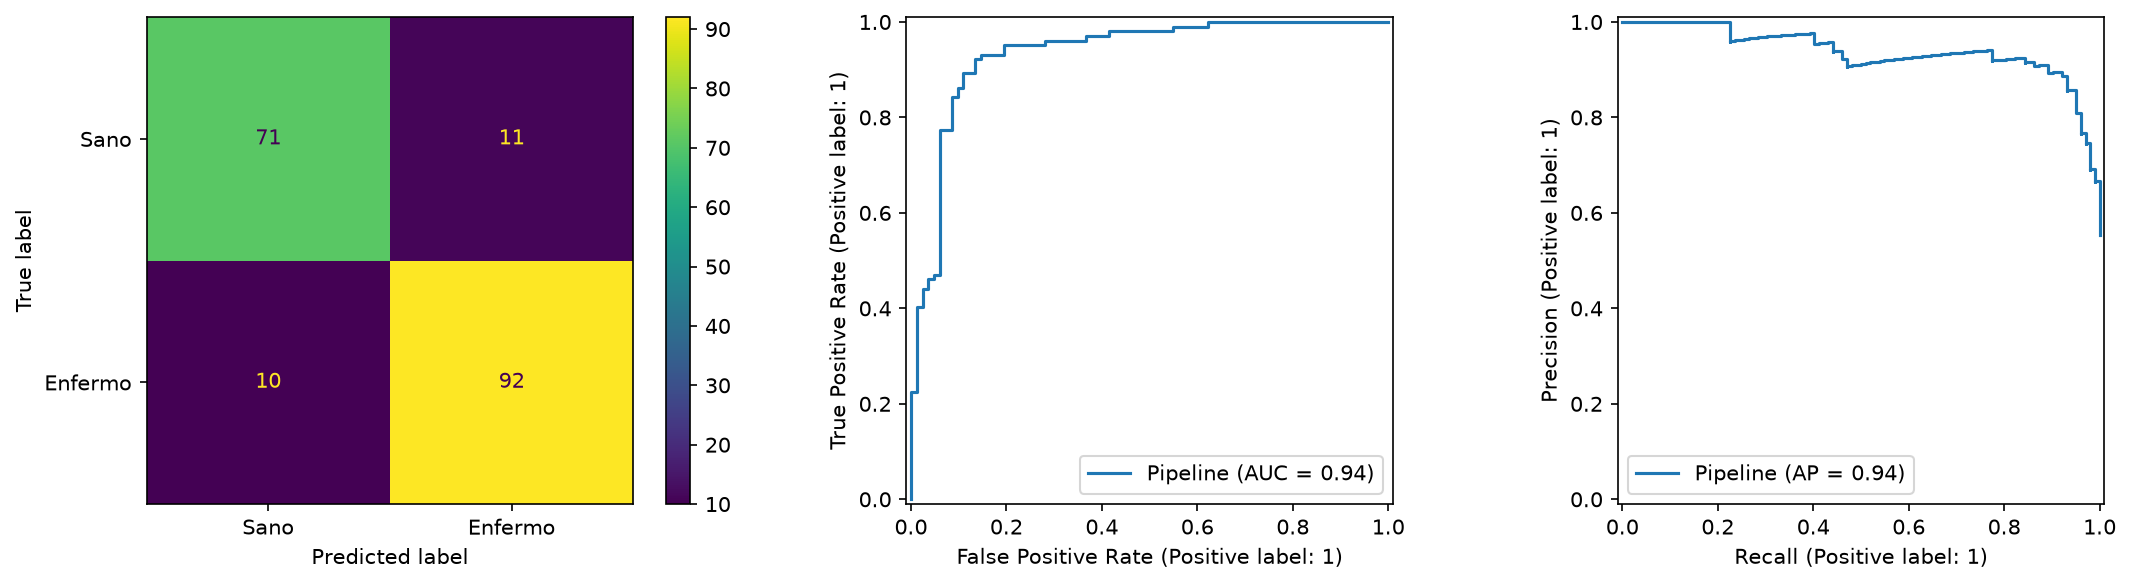

In [43]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay

modelo_final = grid_logreg.best_estimator_

y_pred = modelo_final.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Sano", "Enfermo"]))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
ConfusionMatrixDisplay.from_estimator(modelo_final, X_test, y_test, display_labels=["Sano", "Enfermo"], ax=axes[0])
RocCurveDisplay.from_estimator(modelo_final, X_test, y_test, ax=axes[1])
PrecisionRecallDisplay.from_estimator(modelo_final, X_test, y_test, ax=axes[2])
plt.tight_layout()
plt.show()

En la matriz de confusión vemos que 10 de los 102 pacientes enfermos, fueron clasificados como sanos (FN), es decir casi el 10% de los pacientes enfermos.

Recordemos que el modelo en CV, tuvo un recall de 0.90+-0.04 y un roc-auc de 0.93+-0.02, y ahora en test el recall fue de 0.90 y un roc-auc de 0.94, por lo que el modelo generaliza bien, y no se muestran señales de overfitting.

Ajustamos el umbral de decisión para alcanzar un recall >= 0.95 con la mayor precisión posible

In [44]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import recall_score, precision_score

# Probabilidades "fuera de fold" en train
proba_cv = cross_val_predict(modelo_final, X_train, y_train, cv=kf, method="predict_proba")[:, 1]

filas = []
for t in [0.5, 0.45, 0.4, 0.375, 0.35, 0.325, 0.3, 0.275, 0.25]:
    pred = (proba_cv >= t).astype(int)
    filas.append({"umbral":t,
    "recall": recall_score(y_train, pred),
    "precision": precision_score(y_train, pred)
    })

pd.DataFrame(filas).round(3)

,umbral,recall,precision
0,0.500,0.901,0.857
1,0.450,0.911,0.844
2,0.400,0.919,0.829
3,0.375,0.928,0.823
4,0.350,0.928,0.812
5,0.325,0.936,0.806
6,0.300,0.943,0.797
7,0.275,0.956,0.788
8,0.250,0.965,0.779


Con un umbral de 0.275 cumplimos con el objetivo pedido manteniendo la precisión lo más alto posible, como vemos, al ir bajando el umbral aumenta el recall pero al coste de disminuir la precisión.

              precision    recall  f1-score   support

        Sano       0.94      0.72      0.81        82
     Enfermo       0.81      0.96      0.88       102

    accuracy                           0.85       184
   macro avg       0.87      0.84      0.85       184
weighted avg       0.87      0.85      0.85       184



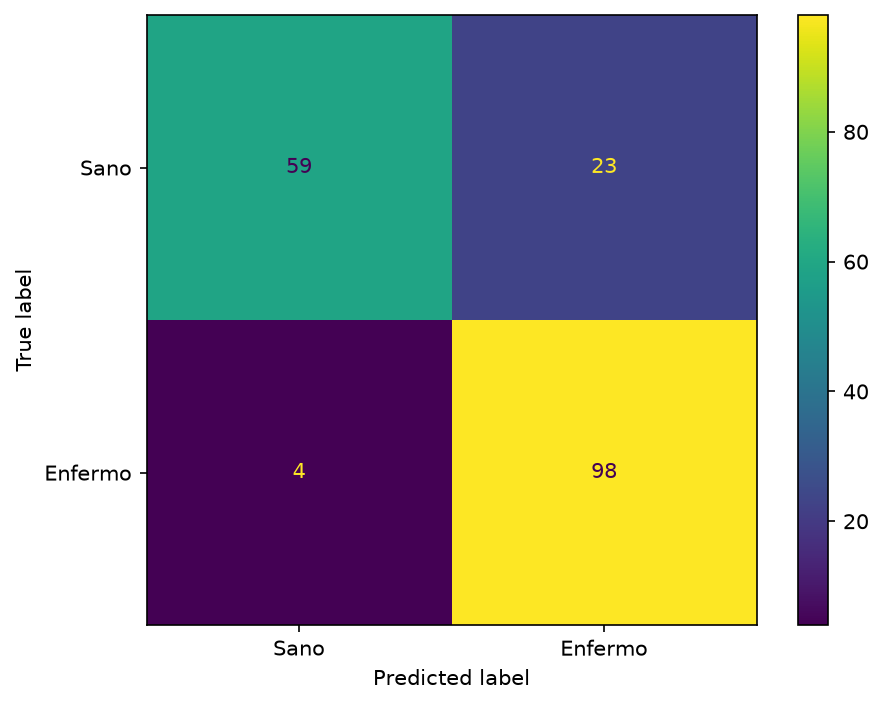

In [45]:
umbral = 0.275
y_pred_t = (modelo_final.predict_proba(X_test)[:, 1] >= umbral).astype(int)
print(classification_report(y_test, y_pred_t, target_names=["Sano", "Enfermo"]))

fig, ax = plt.subplots()
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_t, display_labels=["Sano", "Enfermo"], ax=ax)
plt.tight_layout()
plt.show()

Vemos que ahora el recall es 0.96, lo cual es una gran mejora respecto al anterior de 0.90. Además, coincide con el resultado en train con CV; 0.956, por lo que el umbral escogido funciona. Por lo que tenemos <5% de pacientes enfermos clasificados como sanos, que es lo más costoso en este caso. Por contraparte el recall para paciente sano bajó a un 0.72, aumentando a 23 la cantidad de pacientes sanos clasificados como enfermos en comparación de los 11 en la configuración anterior.

## 09-Interpretación

In [46]:
nombres = modelo_final.named_steps["pre"].get_feature_names_out()
coefs = modelo_final.named_steps["model"].coef_[0]

interpretacion = pd.DataFrame({
    "variable": nombres,
    "coef": coefs,
    "odds_ratio": np.exp(coefs),
}).sort_values("odds_ratio", ascending=False).round(3)

In [47]:
interpretacion

,variable,coef,odds_ratio
7,cat__ChestPainType_ASY,0.904,2.470
17,cat__ST_Slope_Flat,0.875,2.400
6,cat__Sex_M,0.750,2.118
15,cat__ExerciseAngina_Y,0.682,1.978
5,num__missingindicator_Cholesterol,0.619,1.858
11,cat__FastingBS_1,0.476,1.610
4,num__Oldpeak,0.389,1.476
12,cat__RestingECG_LVH,0.186,1.205
1,num__RestingBP,0.064,1.066
0,num__Age,0.041,1.042


In [48]:

coef = interpretacion.set_index("variable")["coef"]

def or_entre(a, b):
    """OR de la categoría a frente a la categoría b (de la misma variable)."""
    return np.exp(coef[a] - coef[b])


print(or_entre("cat__ChestPainType_ASY", "cat__ChestPainType_ATA"))
print(or_entre("cat__ST_Slope_Flat", "cat__ST_Slope_Up"))
print(or_entre("cat__ST_Slope_Down", "cat__ST_Slope_Up"))


3.6038402030977896
5.947672698905182
2.5574227164750947


En Logistic Regression, cada coeficiente indica cuánto cambian los log-odds (el logaritmo de las odds) de tener la enfermedad cuando esa variable sube:
- En las numéricas (escaladas): cuando la variable sube una desviación estándar.
- En las binarias: cuando el paciente pertenece a esa categoría en vez de no pertenecer.
- 3 o más categorías: se interpretan las comparaciones entre categorías.
Qué indican el signo y el tamaño

- Signo positivo: la variable aumenta el riesgo.
- Signo negativo: la variable disminuye el riesgo, es decir, protege.
- Cerca de 0: la variable casi no influye.
- El tamaño (valor absoluto) indica la fuerza del efecto. Un +1 y un −1 son igual de fuertes, pero en direcciones opuestas.

| coef | odds ratio | lectura |
| - | - | - |
| +1 | e¹ ≈ 2,72 | las odds de enfermedad se multiplican por ~2,7 |
| 0 | e⁰ = 1 | sin efecto |
| −1 | e⁻¹ ≈ 0,37 | las odds bajan a ~37 %, o sea, se reducen ~63 % |


## Vemos que para las variables categóricas:

### **Binarias:**

- Sex_M tuvo un coeficiente de 0.75, concordando con la EDA, donde los hombres tenían una mayor tasa de enfermedad. Se asocia a odds 2.12 veces mayores. 

- ExerciseAngina_Y tuvo un coeficiente de 0.68, y concuerda con la EDA, donde la tasa de enfermedad superó el 80% en pacientes que tuvieron Angina después del ejercicio. Tiene un odds 1.98 veces mayores.

### **3 o más valores:**

- ST_Slope_Up tuvo el **valor de coeficiente con mayor fuerza**; -0.908, asociando a una variable que protege, que disminuye el riesgo. Esto concuerda con la EDA donde la variable tuvo una tasa de enfermedad cerca del 0.2, debajo de la tasa global.

- ChestPainType_ASY tuvo el **segundo mayor coeficiente**; 0.90 indicando un fuerte efecto, lo cual concuerda con la EDA, donde se obtuvo que los pacientes con ChestPainType asintomáticos tienen mayor tasa de enfermedad, llegando casi al 80%.

- ST_Slope_Flat tuvo un coeficiente de 0.88, lo que igual concuerda con la EDA, donde se asociaba a una mayor tasa de enfermedad, superando el 80%.

Realizando una comparación de categorías entre las variables:

- Un ChestPainType_ASY frente a un ChestPainType_ATA, se asocia a odds ~3.6 veces mayores.
- Un ST_Slope_Flat , frente a uno ascendente, se asocia a odds ~6 veces mayores.
- Un ST_Slope_Down , frente a uno ascendente, se asocia a odds ~2.6 veces mayores.


### **Numéricas:**

- Oldpeak tuvo un coeficiente de 0.39. Cada desviación estándar adicional de Oldpeak se asocia a odds ~1,5 veces mayores.

- MaxHR tuvo un coeficiente de -0.19. Cada desviación estándar adicional se asocia a odds ~18 % menores; odds ratio de 0.83.

- Cholesterol tuvo un coeficiente de 0.03 y un odds ratio de 1.03, por lo que casi no influye.

    - missingindicator_Cholesterol tuvo un coeficiente de 0.62. Si recordamos, cuando transformamos a nulos los valores 0 de Cholesterol, estos representaban el 19% del dataset total, de los cuales el 88% tienen la enfermedad, por lo que puede ser que el modelo relacionó estos datos y se apoya en esto para predecir. Tiene un odds ratio de 1.86.

- RestingBP y Age apenas influyen, con un coeficiente de 0.06 y 0.04 y odds ratio de 1.07 y 1.04, respectivamente.




Las variables más asociadas a la enfermedad son la pendiente ST (plana o descendente frente a ascendente), el dolor torácico asintomático, el sexo masculino y la angina inducida por ejercicio. Una mayor frecuencia cardíaca máxima se asocia a menor riesgo. El colesterol medido casi no influye, pero su ausencia sí, lo que probablemente refleja el hospital de origen más que un efecto fisiológico. Estas son asociaciones, no causas, y los valores están levemente atenuados por la regularización.


La permutation importance mide cuánto empeora el modelo cuando se "rompe" la información de una variable.

Cómo funciona, paso a paso

1. Con el modelo ya entrenado, se calcula su rendimiento en un conjunto de datos. En nuestro caso, el ROC-AUC en test, que es ~0,935.
2. Se toma una sola columna, por ejemplo ST_Slope, y se desordenan sus valores al azar entre los pacientes. El resto de las columnas no se toca.
3. Se vuelve a calcular el ROC-AUC con esa columna desordenada.
4. Importancia = rendimiento original − rendimiento con la columna desordenada.
5. Se repite varias veces (n_repeats=30) con desórdenes distintos y se reporta la media y la desviación estándar.
6. Se hace lo mismo con cada variable, una por una.

El modelo no se reentrena: siempre es el mismo modelo, que recibe datos con una columna alterada.

La intuición

Desordenar una columna conserva su distribución (mismos valores, mismas proporciones), pero rompe su relación con el objetivo. Si el modelo dependía de esa variable, sus predicciones empeoran mucho. Si no la usaba, el rendimiento casi no cambia.


Diferencia con los coeficientes

- El coeficiente dice cuánto cambia el riesgo cuando cambia una variable, manteniendo fijas las demás.
- La permutation importance dice cuánto depende el rendimiento del modelo de esa variable.

Ventajas

- Funciona con cualquier modelo: regresión logística, Random Forest, KNN…
- Si le pasas el pipeline completo y X_test original, mide la importancia de las variables originales y no de cada columna dummy por separado.
- Mide la importancia con la métrica que elijas (scoring="X").

Limitaciones

- Variables correlacionadas: si dos variables aportan información parecida, al desordenar una la otra compensa, y ambas parecen menos importantes de lo que son.
- Test pequeño: las estimaciones son ruidosas.
- Mide dependencia del modelo, no causalidad: que una variable sea importante para el modelo no significa que cause la enfermedad.

In [49]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(modelo_final, X_test, y_test, scoring="roc_auc", n_repeats= 30, random_state=RANDOM_STATE)

importancias = pd.DataFrame({
    "variable": X_test.columns,
    "media": perm.importances_mean,
    "std": perm.importances_std,
}).sort_values("media", ascending=False).round(3)

importancias

,variable,media,std
10,ST_Slope,0.067,0.012
4,Cholesterol,0.019,0.010
2,ChestPainType,0.014,0.009
9,Oldpeak,0.012,0.005
1,Sex,0.009,0.005
5,FastingBS,0.007,0.003
8,ExerciseAngina,0.007,0.005
7,MaxHR,0.001,0.003
3,RestingBP,0.001,0.001
0,Age,0.000,0.001


Vemos que ST_Slope cambia en un 0.067, es la más alta, y la que más depende el modelo. Coincide con el ST_Slope_Flat vs ST_Slope_Up da un odds ratio de ~6.

Cholesterol es el segundo más alto, cambia en un 0.0190, por lo que igual es una variable importante para el modelo. Sin embargo, su coeficiente es cercano a 0, por lo que la importancia viene en gran medida del indicador faltante. Esto refuerza que el modelo usa la ausencia del dato, probablemente asociada al hospital de origen.

A diferencia de sus coeficientes, ExerciseAngina y Sex apenas cambian el roc-auc, probablemente porque estén correlacionadas con otras variables.

MaxHR (0.001 +- 0.003), RestingBP, Age son prácticamente cero y RestingECG (-0.001) es negativo, por lo que mejoró el roc-auc por azar y equivale a importancia 0.

Junto a esto el test es de 184 pacientes, por lo que las estimaciones son ruidosas.

## Conclusiones

- Se eligió como modelo final a Logistic Regression, debido a que fue uno de los que obtuvo mejor desempeño, y a la vez el menos complejo. Se eligió un C=0.1 a través de GridSearchCV y ajuste a un umbral de 0.275 para aumentar el recall de 0.90 de enfermos a 0.96. Las métricas fueron:

```
precision    recall  f1-score   support

Sano          0.94      0.72      0.81        82
Enfermo       0.81      0.96      0.88       102

accuracy                           0.85       184
macro avg      0.87      0.84      0.85       184
weighted avg   0.87      0.85      0.85       184
```

Las variables claves fueron ST_Slope Flat y Down, ChestPain_ASY, Sex Male y ExerciseAngina_Y. Una mayor frecuencia cardíaca máxima se asocia a un menor riesgo. Se decidió poner como nulos los 0 atípicos de Cholesterol, teniendo en cuenta que estos datos representaban el 19% del dataset. Se tomó esta decisión para evitar un sesgo de selección. Sin embargo, esto produjo que la columna indicadora de falta de Cholesterol tuviera el quinto coeficiente más alto (0.62), esto igual se asocia a que el 88% de esos datos nulos son pacientes enfermos. Por lo que es probable que el modelo aprendiera a identificar que los pacientes sin cholesterol vienen de un hospital en específico.

Las limitaciones:
1. El dataset es pequeño, por lo que afecta la calidad de entrenamiento y evaluación del modelo, por ejemplo en el permutation importance.
2. Los datos son una combinación de 5 hospitales, y de los años 80, por lo que puede afectar la calidad de los datos; diferencia de protocolos, instrumentos, etc, y esto se ve con el hospital que no midió el cholesterol y el otro que lo midió parcialmente.
3. Es solo un modelo predictivo basado en la evaluación de pacientes del mismo dataset, no una herramienta final. Para realizar una herramienta final habría que mejorar la calidad de los datos y cantidad para tener un entrenamiento mejor y evaluación más representativa, obviamente probar con pacientes reales, desplegar el modelo, etc.